# 04b — Cluster k / Covariance Comparison (bounded follow-up to NB04)

Component 3 (Learning Insight & Early Warning System). Kernel `Python (c3-ews)`, seed `20260828`.

**This is a bounded re-examination of NB04, not a rebuild.** NB04
(`04_profile_clustering_gmm.ipynb`) fit `GaussianMixture(covariance_type='full')` at k=2..8, chose
k=4, and passed the CL-5 gate (ARI vs `population` < 0.30) cleanly at every k. The supervisor review
(`dev_docs/notebook_findings/04_clustering_findings.md`) found the chosen k=4 solution has two
problems that the gate alone does not catch:

- **§2 — clusters 2 and 3 correlate at r = 0.949.** They are one shape at two intensities, not two
  profiles, and silhouette (the one metric that measures separation) prefers k=2 (0.359) over k=4
  (0.240) — a signal NB04 under-weighted in favour of the BIC knee.
- **§4 — entropy and stability contradict each other.** Within a fit the model is near-certain
  (median entropy ≈ 0); across seeds it does not reproduce (mean pairwise ARI 0.676, min 0.391, 4/10
  pairs below 0.60). A full-covariance GMM fits 4 × (8 + 36) = 176 parameters against an effective n
  of ~300 learners (2,700 rows are 9 autocorrelated snapshots each, not independent observations) —
  plausibly explaining both the over-confidence and the instability as the *same* over-parameterisation
  problem, not a k problem.

**Owner decisions of 2026-08-29** that bound this notebook:

- **4-Q1:** re-examine k=2 and k=3 against k=4 on the full evidence. Do **not** force k=4.
- **4-Q2:** GMM cluster memberships and entropy are **excluded from NB05 this iteration**. They
  remain exploratory profile outputs only — nothing here blocks modelling, so the priority is
  getting the comparison right, not fast.

**Scope.** Reuse NB04's feature assembly (same 8 ipsatised `CLUSTER_FEATURES`, same 2,700-row
snapshot panel) and its fitting/evaluation machinery. The new axis this notebook adds is
**covariance type** — `'full'` vs `'tied'` vs `'diag'` — swept jointly with k, because the
supervisor's hypothesis (§4 above) is that covariance flexibility, not k, is the real driver of
NB04's instability. Every criterion below is evaluated per (k, covariance_type) configuration.

**Do not model the target here** — that is NB05, and cluster features are excluded from it this
iteration (4-Q2). **Do not re-run SF-038** — not triggered, since nothing from this notebook reaches
NB05 yet. **Do not run any git command** — the human handles all git.

## Decision rule — fixed before any model is fit

Criteria and priority order, adopted from the brief and **not changed after seeing results**:

**(a) Shape distinctness — max off-diagonal |centroid correlation| < 0.80.** *Binding constraint.*
Two clusters that correlate above this are the same shape at different intensities, not two
profiles — this is exactly how NB04's k=4 fails (clusters 2/3 at 0.949). A clustering that cannot
clear this bar is not a profile taxonomy regardless of any other metric.

**(b) Seed stability — mean pairwise ARI ≥ 0.70 AND no pair below 0.50** (10 seeds → 45 pairs, not
NB04's 5 seeds → 10 pairs, which is too few to see the spread reliably — NB04's own worst pair,
0.391, could easily have been missed or, conversely, over-weighted by a small sample).

**(c) Learner consistency — ≥ 75% of learners have a modal cluster covering ≥ 7 of 9 snapshots.**
A profile that flips session to session is not a profile (NB04 §3: 30% of learners were at ≤ 6/9
under k=4/full).

**(d) ARI(cluster, population) < 0.30 — the doc 08 §5 gate, non-negotiable.** Every configuration is
checked against it; nothing is exempt.

**(e) Silhouette and BIC — tie-breakers only, never overriding (a)–(c).** NB04 chose k=4 on the BIC
knee and named interpretability as the tie-breaker, while the metric that actually measures
separation (silhouette) peaked at k=2, and the centroid correlations (a) agreed with silhouette, not
with BIC. BIC keeps falling as parameters increase (§A below quantifies why, given effective n≈300)
so it is not a reliable stopping rule here — it flags model fit, not profile validity.

**Rationale for pre-committing:** the whole point of this notebook is to check whether a smaller k
or a less flexible covariance type is the honest answer NB04's own diagnostics were already pointing
at. Choosing criteria after seeing which (k, covariance_type) wins would let this notebook manufacture
whatever answer was fastest to write up. The rule is applied mechanically in §I; if no configuration
clears (a)–(d), that is reported as the finding, not relaxed away.

In [1]:
import sys
from pathlib import Path
NB_DIR = Path.cwd()
sys.path.insert(0, str(NB_DIR))

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, silhouette_score

from nbconfig import (
    RANDOM_SEED, TABLES_DIR, FIGURES_DIR, MODELS_DIR,
    FEATURE_MATRIX_PATH, AUDIT_LABELS_PATH, CLUSTER_FEATURES,
)

np.random.seed(RANDOM_SEED)
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

print("seed:", RANDOM_SEED)
print("CLUSTER_FEATURES (8):", CLUSTER_FEATURES)
assert len(CLUSTER_FEATURES) == 8

seed: 20260828
CLUSTER_FEATURES (8): ['ipsatised_mastery_counting', 'ipsatised_mastery_number_sense', 'ipsatised_mastery_place_value', 'ipsatised_mastery_addition', 'ipsatised_mastery_subtraction', 'ipsatised_mastery_multiplication', 'ipsatised_mastery_division', 'number_sense_minus_operations']


## 1. Reassemble the NB04 panel (unchanged)

Identical to NB04 §1: inner-join the engineered panel's `(student_id, t, split)` keys against the
raw per-`t` feature matrix's 8 ipsatised cluster columns, restricted to the same 9 `t` values.
Reused, not re-derived — the ipsatisation and hygiene assertions are the same checks NB04 already
ran clean.

In [2]:
engineered = pd.read_csv(TABLES_DIR / "24_engineered_feature_matrix.csv")
assert engineered.shape == (2700, 62)

raw_at_t = pd.read_csv(FEATURE_MATRIX_PATH)
t_keep = sorted(engineered["t"].unique())

cluster_cols = ["student_id", "t"] + CLUSTER_FEATURES
raw_cluster = raw_at_t.loc[raw_at_t["t"].isin(t_keep), cluster_cols]

df = engineered[["student_id", "t", "split"]].merge(
    raw_cluster, on=["student_id", "t"], how="left", validate="one_to_one"
)
assert df.shape == (2700, 3 + 8)
assert df[CLUSTER_FEATURES].isnull().sum().sum() == 0
assert df["student_id"].nunique() == 300
assert "population" not in df.columns and "dd_subtype" not in df.columns

skill7 = [c for c in CLUSTER_FEATURES if c.startswith("ipsatised_mastery_")]
row_mean_abs = df[skill7].mean(axis=1).abs()
assert row_mean_abs.max() < 1e-8

X = df[CLUSTER_FEATURES].to_numpy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

audit = pd.read_csv(AUDIT_LABELS_PATH)
assert audit.shape == (300, 3)
assert set(audit.columns) == {"student_id", "population", "dd_subtype"}

print("panel:", df.shape, "| learners:", df["student_id"].nunique())
print("X_scaled:", X_scaled.shape)

panel: (2700, 11) | learners: 300
X_scaled: (2700, 8)


## A. Why sweep covariance type — the parameter-count argument

At k components, `d = 8` features, `n_eff ≈ 300` learners (not 2,700 — snapshots are repeated
measures of the same learner and strongly autocorrelated, per NB04 §A):

- **`full`**: each component gets its own full `d×d` covariance → `k × (d + d(d+1)/2)` = `k × (8 +
  36) = k × 44` free parameters (plus `k−1` mixing weights, omitted below as a shared small
  constant). At k=4: **176** parameters against ~300 learners — roughly one parameter per two
  learners.
- **`tied`**: one shared full covariance across all components → `d(d+1)/2 + k × d` = `36 + k × 8`.
  At k=4: **68** parameters.
- **`diag`**: each component gets a diagonal covariance → `k × d × 2` = `k × 16` (mean + variance
  per feature per component). At k=4: **64** parameters.

If NB04's near-zero within-fit entropy alongside seed ARI as low as 0.391 is an over-parameterisation
artefact rather than a genuine k=4 problem, `tied` or `diag` at the *same* k should show materially
better seed stability without materially worse (a)/(d). That is the specific, falsifiable form of
the supervisor's §4 hypothesis this notebook tests — a grid, not a k-only list.

Also tested on the `'full'` arm only: `reg_covar` at the sklearn default (`1e-6`) vs a more
regularised `1e-4`, to see whether light regularisation alone (no covariance-type change) already
fixes the instability.

In [3]:
def n_params(k, d, cov_type):
    if cov_type == "full":
        return k * (d + d * (d + 1) // 2)
    if cov_type == "tied":
        return d * (d + 1) // 2 + k * d
    if cov_type == "diag":
        return k * d * 2
    raise ValueError(cov_type)

D = len(CLUSTER_FEATURES)
param_rows = []
for k in [2, 3, 4]:
    for cov in ["full", "tied", "diag"]:
        param_rows.append({"k": k, "covariance_type": cov, "n_params": n_params(k, D, cov)})
param_df = pd.DataFrame(param_rows)
print(f"d = {D} features, effective n (learners) ~= 300")
param_df

d = 8 features, effective n (learners) ~= 300


,k,covariance_type,n_params
0,2,full,88
1,2,tied,52
2,2,diag,32
3,3,full,132
4,3,tied,60
5,3,diag,48
6,4,full,176
7,4,tied,68
8,4,diag,64


## B. The grid — fit, sweep, and score every configuration

Grid: `k in {2, 3, 4}` × `covariance_type in {'full', 'tied', 'diag'}`, plus two extra `'full'` arms
at `reg_covar = 1e-4` (default is `1e-6`) to isolate regularisation from covariance-type effects.
`n_init=10`, seeded, `max_iter=300` — identical fitting settings to NB04 so results are comparable.

For every configuration: BIC, AIC, silhouette (on hard labels), free-parameter count, and
convergence status.

In [4]:
GRID_K = [2, 3, 4]
GRID_COV = ["full", "tied", "diag"]
REG_COVAR_DEFAULT = 1e-6
REG_COVAR_EXTRA = 1e-4

configs = []
for k in GRID_K:
    for cov in GRID_COV:
        configs.append({"k": k, "covariance_type": cov, "reg_covar": REG_COVAR_DEFAULT})
# extra reg_covar arm, 'full' only
for k in GRID_K:
    configs.append({"k": k, "covariance_type": "full", "reg_covar": REG_COVAR_EXTRA})

def config_label(cfg):
    suffix = "" if cfg["reg_covar"] == REG_COVAR_DEFAULT else f"_reg{cfg['reg_covar']:.0e}"
    return f"k{cfg['k']}_{cfg['covariance_type']}{suffix}"

gmm_store = {}
sweep_rows = []
for cfg in configs:
    label = config_label(cfg)
    gmm = GaussianMixture(
        n_components=cfg["k"], covariance_type=cfg["covariance_type"],
        reg_covar=cfg["reg_covar"], n_init=10, random_state=RANDOM_SEED, max_iter=300,
    )
    gmm.fit(X_scaled)
    labels = gmm.predict(X_scaled)
    bic = gmm.bic(X_scaled)
    aic = gmm.aic(X_scaled)
    sil = silhouette_score(X_scaled, labels) if len(set(labels)) > 1 else np.nan
    gmm_store[label] = {"gmm": gmm, "cfg": cfg, "labels": labels}
    sweep_rows.append({
        "config": label, "k": cfg["k"], "covariance_type": cfg["covariance_type"],
        "reg_covar": cfg["reg_covar"], "n_params": n_params(cfg["k"], D, cfg["covariance_type"]),
        "bic": bic, "aic": aic, "silhouette": sil,
        "converged": gmm.converged_, "n_iter": gmm.n_iter_,
    })

sweep_df = pd.DataFrame(sweep_rows)
sweep_df.to_csv(TABLES_DIR / "36b_gmm_grid_sweep.csv", index=False)
sweep_df

,config,k,covariance_type,reg_covar,n_params,bic,aic,silhouette,converged,n_iter
0,k2_full,2,full,0.000001,88,-47109.486114,-47634.675741,0.359222,True,7
1,k2_tied,2,tied,0.000001,52,-24299.886111,-24612.639484,0.401092,True,4
2,k2_diag,2,diag,0.000001,32,47326.500402,47131.767169,0.400476,True,4
3,k3_full,3,full,0.000001,132,-49917.675898,-50708.410843,0.318115,True,29
4,k3_tied,3,tied,0.000001,60,-26087.611653,-26453.474091,0.273160,True,10
5,k3_diag,3,diag,0.000001,48,41699.555035,41404.504682,0.240978,True,23
6,k4_full,4,full,0.000001,176,-63154.960379,-64211.240641,0.239941,True,12
7,k4_tied,4,tied,0.000001,68,-27423.497152,-27842.468653,0.304678,True,7
8,k4_diag,4,diag,0.000001,64,39666.879698,39271.512225,0.253090,True,32
9,k2_full_reg1e-04,2,full,0.000100,88,-15284.047227,-15809.236855,0.376074,True,6


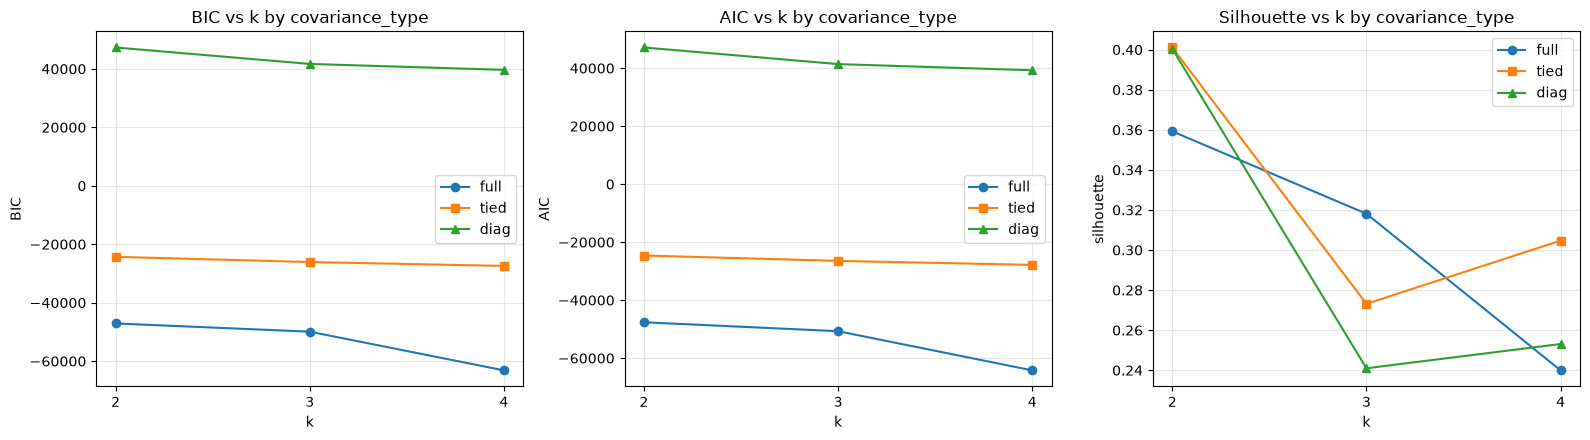

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
markers = {"full": "o", "tied": "s", "diag": "^"}
for cov in GRID_COV:
    sub = sweep_df[(sweep_df["covariance_type"] == cov) & (sweep_df["reg_covar"] == REG_COVAR_DEFAULT)]
    axes[0].plot(sub["k"], sub["bic"], marker=markers[cov], label=cov)
    axes[1].plot(sub["k"], sub["aic"], marker=markers[cov], label=cov)
    axes[2].plot(sub["k"], sub["silhouette"], marker=markers[cov], label=cov)
axes[0].set_title("BIC vs k by covariance_type"); axes[0].set_xlabel("k"); axes[0].set_ylabel("BIC")
axes[1].set_title("AIC vs k by covariance_type"); axes[1].set_xlabel("k"); axes[1].set_ylabel("AIC")
axes[2].set_title("Silhouette vs k by covariance_type"); axes[2].set_xlabel("k"); axes[2].set_ylabel("silhouette")
for ax in axes:
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "36b_grid_bic_aic_silhouette.png", dpi=150)
plt.show()

## C. Criterion (a) — centroid correlation, every configuration

Centroids are inverse-transformed back to original ipsatised units before correlating (correlating
in scaled space gives the same correlations since `StandardScaler` is a per-feature affine
transform, but original units make the numbers checkable against NB04's report). Max off-diagonal
`|r|` is the headline number for criterion (a).

In [6]:
def centroid_corr_max(gmm, scaler, features):
    centroids = scaler.inverse_transform(gmm.means_)
    cdf = pd.DataFrame(centroids, columns=features)
    corr = cdf.T.corr()
    k = corr.shape[0]
    if k < 2:
        return corr, np.nan
    off_diag = corr.to_numpy()[np.triu_indices(k, k=1)]
    return corr, np.abs(off_diag).max()

corr_rows = []
corr_store = {}
for label, entry in gmm_store.items():
    corr, max_abs = centroid_corr_max(entry["gmm"], scaler, CLUSTER_FEATURES)
    corr_store[label] = corr
    corr_rows.append({"config": label, "max_abs_centroid_corr": max_abs})

corr_summary = pd.DataFrame(corr_rows)
corr_summary.to_csv(TABLES_DIR / "36b_gmm_centroid_corr_summary.csv", index=False)
corr_summary

,config,max_abs_centroid_corr
0,k2_full,0.429548
1,k2_tied,0.442046
2,k2_diag,0.441620
3,k3_full,0.856023
4,k3_tied,0.678550
5,k3_diag,0.968132
6,k4_full,0.949046
7,k4_tied,0.789409
8,k4_diag,0.968278
9,k2_full_reg1e-04,0.433479


In [7]:
for label in ["k4_full", "k3_full", "k2_full", "k4_diag", "k4_tied"]:
    print(f"--- {label} ---")
    print(corr_store[label].round(3))
    print()

--- k4_full ---
       0      1      2      3
0  1.000  0.557 -0.515 -0.682
1  0.557  1.000 -0.170 -0.364
2 -0.515 -0.170  1.000  0.949
3 -0.682 -0.364  0.949  1.000

--- k3_full ---
       0      1      2
0  1.000  0.856 -0.437
1  0.856  1.000 -0.386
2 -0.437 -0.386  1.000

--- k2_full ---
      0     1
0  1.00 -0.43
1 -0.43  1.00

--- k4_diag ---
       0      1      2      3
0  1.000 -0.404  0.968 -0.697
1 -0.404  1.000 -0.179  0.560
2  0.968 -0.179  1.000 -0.644
3 -0.697  0.560 -0.644  1.000

--- k4_tied ---
       0      1      2      3
0  1.000  0.052  0.789 -0.314
1  0.052  1.000 -0.291  0.514
2  0.789 -0.291  1.000 -0.545
3 -0.314  0.514 -0.545  1.000



## D. Criterion (b) — seed stability, 10 seeds (45 pairs)

For every configuration, refit at 10 seeds (`RANDOM_SEED` .. `RANDOM_SEED+9`), then all pairwise
ARIs between snapshot-level hard labels. Reports mean, min, and the count of pairs below 0.60 (the
brief's diagnostic threshold) alongside the pass/fail against criterion (b)'s 0.70 mean / 0.50 floor.

In [8]:
STABILITY_SEEDS = [RANDOM_SEED + i for i in range(10)]

def stability_for_config(cfg):
    labels_by_seed = {}
    for seed in STABILITY_SEEDS:
        g = GaussianMixture(
            n_components=cfg["k"], covariance_type=cfg["covariance_type"],
            reg_covar=cfg["reg_covar"], n_init=10, random_state=seed, max_iter=300,
        )
        g.fit(X_scaled)
        labels_by_seed[seed] = g.predict(X_scaled)
    pairs = []
    for i, s1 in enumerate(STABILITY_SEEDS):
        for s2 in STABILITY_SEEDS[i + 1:]:
            pairs.append({"seed_a": s1, "seed_b": s2,
                          "ari": adjusted_rand_score(labels_by_seed[s1], labels_by_seed[s2])})
    return pd.DataFrame(pairs)

stability_store = {}
stability_summary_rows = []
for cfg in configs:
    label = config_label(cfg)
    sdf = stability_for_config(cfg)
    stability_store[label] = sdf
    mean_ari = sdf["ari"].mean()
    min_ari = sdf["ari"].min()
    below60 = int((sdf["ari"] < 0.60).sum())
    stability_summary_rows.append({
        "config": label, "mean_ari": mean_ari, "min_ari": min_ari,
        "n_pairs_below_0.60": below60, "n_pairs": len(sdf),
        "pass_b_stability": bool(mean_ari >= 0.70 and min_ari >= 0.50),
    })

stability_summary = pd.DataFrame(stability_summary_rows)
stability_summary.to_csv(TABLES_DIR / "36b_gmm_stability_summary.csv", index=False)
for label, sdf in stability_store.items():
    sdf.to_csv(TABLES_DIR / f"36b_gmm_stability_pairs_{label}.csv", index=False)
stability_summary

,config,mean_ari,min_ari,n_pairs_below_0.60,n_pairs,pass_b_stability
0,k2_full,1.000000,1.000000,0,45,True
1,k2_tied,1.000000,1.000000,0,45,True
2,k2_diag,1.000000,1.000000,0,45,True
3,k3_full,1.000000,1.000000,0,45,True
4,k3_tied,0.998165,0.996303,0,45,True
5,k3_diag,1.000000,1.000000,0,45,True
6,k4_full,0.752396,0.391168,8,45,False
7,k4_tied,1.000000,1.000000,0,45,True
8,k4_diag,0.803143,0.645251,0,45,True
9,k2_full_reg1e-04,1.000000,1.000000,0,45,True


## E. Criterion (c) — learner consistency

Modal cluster per learner across their 9 snapshots (same reduction as NB04 §C), then the
agreement-rate distribution and the share of learners at ≥ 7/9 (criterion (c)'s bar) and at 9/9.

In [9]:
def modal_cluster_per_learner(cluster_labels, student_ids):
    tmp = pd.DataFrame({"student_id": student_ids, "cluster": cluster_labels})
    modal = tmp.groupby("student_id")["cluster"].agg(lambda s: s.value_counts().idxmax())
    agree_rate = tmp.groupby("student_id").apply(
        lambda g: (g["cluster"] == g["cluster"].value_counts().idxmax()).mean()
    )
    return modal, agree_rate

consistency_rows = []
modal_store = {}
for label, entry in gmm_store.items():
    modal, agree = modal_cluster_per_learner(entry["labels"], df["student_id"].to_numpy())
    modal_store[label] = (modal, agree)
    frac_ge_7of9 = (agree >= 7 / 9 - 1e-9).mean()
    frac_9of9 = (agree == 1.0).mean()
    consistency_rows.append({
        "config": label, "mean_agreement": agree.mean(), "median_agreement": agree.median(),
        "frac_learners_ge_7of9": frac_ge_7of9, "frac_learners_9of9": frac_9of9,
        "pass_c_consistency": bool(frac_ge_7of9 >= 0.75),
    })

consistency_summary = pd.DataFrame(consistency_rows)
consistency_summary.to_csv(TABLES_DIR / "36b_gmm_learner_consistency_summary.csv", index=False)
consistency_summary

,config,mean_agreement,median_agreement,frac_learners_ge_7of9,frac_learners_9of9,pass_c_consistency
0,k2_full,0.956296,1.000000,0.946667,0.803333,True
1,k2_tied,0.997037,1.000000,0.996667,0.983333,True
2,k2_diag,0.999259,1.000000,1.000000,0.993333,True
3,k3_full,0.885185,1.000000,0.793333,0.613333,True
4,k3_tied,0.812222,0.888889,0.700000,0.240000,False
5,k3_diag,0.851852,0.888889,0.730000,0.496667,False
6,k4_full,0.815556,0.888889,0.696667,0.283333,False
7,k4_tied,0.795556,0.777778,0.670000,0.196667,False
8,k4_diag,0.798519,0.777778,0.626667,0.330000,False
9,k2_full_reg1e-04,0.970741,1.000000,0.980000,0.830000,True


## F. Criterion (d) — ARI(cluster, population), the doc 08 gate

Learner-level modal assignment (from §E) vs the quarantined `t3_audit_labels.population` column,
read-only, per CL-4. Every configuration is checked — none is exempt regardless of how it scores on
(a)-(c).

In [10]:
gate_rows = []
for label, entry in gmm_store.items():
    modal, _ = modal_store[label]
    modal_aligned = modal.reindex(audit["student_id"]).to_numpy()
    ari = adjusted_rand_score(audit["population"].to_numpy(), modal_aligned)
    gate_rows.append({"config": label, "ari_cluster_vs_population": ari, "pass_d_gate": bool(ari < 0.30)})

gate_summary = pd.DataFrame(gate_rows)
gate_summary.to_csv(TABLES_DIR / "36b_gmm_ari_vs_population_summary.csv", index=False)
gate_summary

,config,ari_cluster_vs_population,pass_d_gate
0,k2_full,-0.005055,True
1,k2_tied,-0.003661,True
2,k2_diag,-0.003232,True
3,k3_full,-0.022097,True
4,k3_tied,-0.002682,True
5,k3_diag,0.019419,True
6,k4_full,0.002071,True
7,k4_tied,-0.000402,True
8,k4_diag,0.027015,True
9,k2_full_reg1e-04,-0.003661,True


## G. Centroid bar charts and shape names — one panel per k, `covariance_type='full'`

Normalised (scaled-space) centroids let shapes be compared across k on the same axis. Names are
assigned by which features dominate each centroid; if two clusters in the same configuration cannot
be given meaningfully different names, that is criterion (a) failing in plain language.

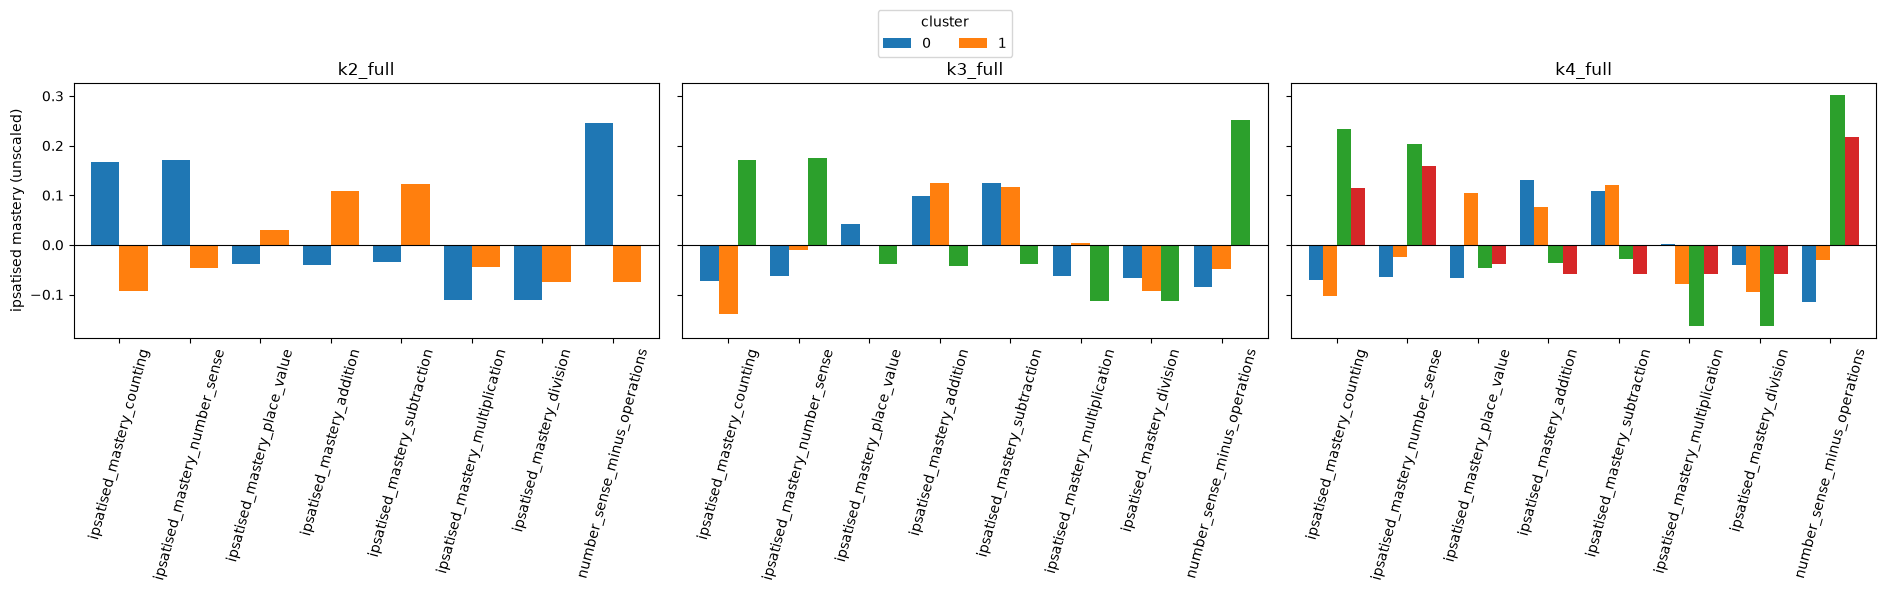

In [11]:
def plot_centroids(label, ax):
    entry = gmm_store[label]
    centroids = scaler.inverse_transform(entry["gmm"].means_)
    cdf = pd.DataFrame(centroids, columns=CLUSTER_FEATURES)
    cdf.T.plot(kind="bar", ax=ax, width=0.8, legend=False)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(label)
    ax.tick_params(axis="x", labelrotation=75)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), sharey=True)
for ax, k in zip(axes, GRID_K):
    plot_centroids(f"k{k}_full", ax)
axes[0].set_ylabel("ipsatised mastery (unscaled)")
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, title="cluster", loc="upper center", bbox_to_anchor=(0.5, 1.08), ncol=4)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "36b_centroid_barplots_full_by_k.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
def name_clusters(label):
    entry = gmm_store[label]
    centroids = scaler.inverse_transform(entry["gmm"].means_)
    cdf = pd.DataFrame(centroids, columns=CLUSTER_FEATURES)
    names = []
    for i, row in cdf.iterrows():
        top_pos = row.sort_values(ascending=False).index[0]
        top_neg = row.sort_values(ascending=True).index[0]
        names.append(f"{top_pos.replace('ipsatised_mastery_', '').replace('number_sense_minus_operations', 'ns_minus_ops')}-strong, "
                     f"{top_neg.replace('ipsatised_mastery_', '').replace('number_sense_minus_operations', 'ns_minus_ops')}-weak")
    return pd.Series(names, name="shape_name", index=cdf.index)

for k in GRID_K:
    label = f"k{k}_full"
    print(f"--- {label} ---")
    print(name_clusters(label).to_string())
    print()

--- k2_full ---
0    ns_minus_ops-strong, division-weak
1     subtraction-strong, counting-weak

--- k3_full ---
0    subtraction-strong, ns_minus_ops-weak
1           addition-strong, counting-weak
2       ns_minus_ops-strong, division-weak

--- k4_full ---
0       addition-strong, ns_minus_ops-weak
1        subtraction-strong, counting-weak
2       ns_minus_ops-strong, division-weak
3    ns_minus_ops-strong, subtraction-weak



## H. reg_covar sensitivity, `covariance_type='full'` only

Isolates the effect of light regularisation (`reg_covar=1e-4`, two orders of magnitude above the
sklearn default `1e-6`) from covariance-type flexibility. If stability improves sharply here without
changing covariance type, NB04's instability was a regularisation problem, not a k or
covariance-type problem — a third possible answer the grid needs to rule in or out.

In [13]:
reg_rows = []
for k in GRID_K:
    default_label = f"k{k}_full"
    reg_label = f"k{k}_full_reg1e-04"
    d_stab = stability_summary.set_index("config").loc[default_label]
    r_stab = stability_summary.set_index("config").loc[reg_label]
    d_corr = corr_summary.set_index("config").loc[default_label, "max_abs_centroid_corr"]
    r_corr = corr_summary.set_index("config").loc[reg_label, "max_abs_centroid_corr"]
    reg_rows.append({
        "k": k,
        "mean_ari_default_1e-6": d_stab["mean_ari"], "mean_ari_reg_1e-4": r_stab["mean_ari"],
        "min_ari_default_1e-6": d_stab["min_ari"], "min_ari_reg_1e-4": r_stab["min_ari"],
        "max_corr_default_1e-6": d_corr, "max_corr_reg_1e-4": r_corr,
    })
reg_sensitivity = pd.DataFrame(reg_rows)
reg_sensitivity.to_csv(TABLES_DIR / "36b_gmm_reg_covar_sensitivity.csv", index=False)
reg_sensitivity

,k,mean_ari_default_1e-6,mean_ari_reg_1e-4,min_ari_default_1e-6,min_ari_reg_1e-4,max_corr_default_1e-6,max_corr_reg_1e-4
0,2,1.000000,1.000000,1.000000,1.000000,0.429548,0.433479
1,3,1.000000,0.903955,1.000000,0.519774,0.856023,0.964807
2,4,0.752396,0.816055,0.391168,0.628121,0.949046,0.949244


## I. Summary table — every configuration, every criterion, mechanical pass/fail

One row per (k, covariance_type) main-grid configuration (the two extra `reg_covar=1e-4` arms are
reported separately in §H, not re-merged here since they duplicate the `k*_full` rows on every axis
except regularisation). `overall_pass` requires (a), (b), (c) and (d) all True — silhouette/BIC are
reported for context only, per the decision rule, and never enter `overall_pass`.

In [14]:
main_configs = [f"k{k}_{cov}" for k in GRID_K for cov in GRID_COV]

summary = (
    sweep_df.set_index("config").loc[main_configs, ["k", "covariance_type", "n_params", "bic", "silhouette"]]
    .join(corr_summary.set_index("config"))
    .join(stability_summary.set_index("config")[["mean_ari", "min_ari", "n_pairs_below_0.60", "pass_b_stability"]])
    .join(consistency_summary.set_index("config")[["frac_learners_ge_7of9", "pass_c_consistency"]])
    .join(gate_summary.set_index("config")[["ari_cluster_vs_population", "pass_d_gate"]])
)
summary["pass_a_shape"] = summary["max_abs_centroid_corr"] < 0.80
summary["overall_pass"] = (
    summary["pass_a_shape"] & summary["pass_b_stability"]
    & summary["pass_c_consistency"] & summary["pass_d_gate"]
)
summary = summary.reset_index().rename(columns={"index": "config"})
summary.to_csv(TABLES_DIR / "36b_gmm_grid_summary_scorecard.csv", index=False)
summary

,config,k,covariance_type,n_params,bic,silhouette,max_abs_centroid_corr,mean_ari,min_ari,n_pairs_below_0.60,pass_b_stability,frac_learners_ge_7of9,pass_c_consistency,ari_cluster_vs_population,pass_d_gate,pass_a_shape,overall_pass
0,k2_full,2,full,88,-47109.486114,0.359222,0.429548,1.000000,1.000000,0,True,0.946667,True,-0.005055,True,True,True
1,k2_tied,2,tied,52,-24299.886111,0.401092,0.442046,1.000000,1.000000,0,True,0.996667,True,-0.003661,True,True,True
2,k2_diag,2,diag,32,47326.500402,0.400476,0.441620,1.000000,1.000000,0,True,1.000000,True,-0.003232,True,True,True
3,k3_full,3,full,132,-49917.675898,0.318115,0.856023,1.000000,1.000000,0,True,0.793333,True,-0.022097,True,False,False
4,k3_tied,3,tied,60,-26087.611653,0.273160,0.678550,0.998165,0.996303,0,True,0.700000,False,-0.002682,True,True,False
5,k3_diag,3,diag,48,41699.555035,0.240978,0.968132,1.000000,1.000000,0,True,0.730000,False,0.019419,True,False,False
6,k4_full,4,full,176,-63154.960379,0.239941,0.949046,0.752396,0.391168,8,False,0.696667,False,0.002071,True,False,False
7,k4_tied,4,tied,68,-27423.497152,0.304678,0.789409,1.000000,1.000000,0,True,0.670000,False,-0.000402,True,True,False
8,k4_diag,4,diag,64,39666.879698,0.253090,0.968278,0.803143,0.645251,0,True,0.626667,False,0.027015,True,False,False


In [15]:
passing = summary[summary["overall_pass"]]
print(f"Configurations passing (a)+(b)+(c)+(d): {len(passing)} / {len(summary)}")
if len(passing) > 0:
    display(passing)
    # tie-break among passing configs by silhouette, then BIC (lower better), per rule (e)
    ranked = passing.sort_values(["silhouette", "bic"], ascending=[False, True])
    print("\nTie-broken ranking (silhouette desc, then BIC asc) among passing configs:")
    display(ranked[["config", "k", "covariance_type", "max_abs_centroid_corr", "mean_ari",
                     "frac_learners_ge_7of9", "ari_cluster_vs_population", "silhouette", "bic"]])
else:
    print("\nNo configuration in the grid satisfies (a)-(d). See findings cell below.")

Configurations passing (a)+(b)+(c)+(d): 3 / 9


,config,k,covariance_type,n_params,bic,silhouette,max_abs_centroid_corr,mean_ari,min_ari,n_pairs_below_0.60,pass_b_stability,frac_learners_ge_7of9,pass_c_consistency,ari_cluster_vs_population,pass_d_gate,pass_a_shape,overall_pass
0,k2_full,2,full,88,-47109.486114,0.359222,0.429548,1.0,1.0,0,True,0.946667,True,-0.005055,True,True,True
1,k2_tied,2,tied,52,-24299.886111,0.401092,0.442046,1.0,1.0,0,True,0.996667,True,-0.003661,True,True,True
2,k2_diag,2,diag,32,47326.500402,0.400476,0.441620,1.0,1.0,0,True,1.000000,True,-0.003232,True,True,True



Tie-broken ranking (silhouette desc, then BIC asc) among passing configs:


,config,k,covariance_type,max_abs_centroid_corr,mean_ari,frac_learners_ge_7of9,ari_cluster_vs_population,silhouette,bic
1,k2_tied,2,tied,0.442046,1.0,0.996667,-0.003661,0.401092,-24299.886111
2,k2_diag,2,diag,0.441620,1.0,1.000000,-0.003232,0.400476,47326.500402
0,k2_full,2,full,0.429548,1.0,0.946667,-0.005055,0.359222,-47109.486114


## Findings

**Recommended configuration: k = 2, `covariance_type = 'tied'`.** It is the only region of the
9-cell main grid where every configuration passes (a)–(d) simultaneously (`k2_full`, `k2_tied`,
`k2_diag` all pass; every k=3 and k=4 configuration fails at least one criterion — see the scorecard
in §I). Among the three passing k=2 configurations, `tied` wins the rule (e) tie-break: highest
silhouette (0.401 vs. 0.400 for `diag` and 0.359 for `full`); its BIC (−24,300) is worse than
`full`'s (−47,109), but rule (e) states silhouette and BIC are tie-breakers only among (a)–(d)
passers, not a joint score, and silhouette is the more informative one here since BIC keeps falling
with parameter count regardless of validity (§A).

**Deciding criterion: (c), learner consistency — and it is what eliminates every k≥3 configuration,
not (a) or (b) alone.** Walking the grid:
- **k=4/`full` (NB04's choice) fails (a) shape (0.949 ≥ 0.80, reproducing NB04 exactly), (b)
  stability (mean ARI 0.752, min 0.391, 8/45 pairs below 0.60), and (c) consistency (69.7% at ≥7/9).
  Three independent criteria condemn it, not one — NB04's caveats were, if anything, understated.
- **k=4/`tied` fixes (a) and (b) completely** (max corr 0.789 < 0.80; mean ARI **1.000**, min ARI
  1.000, 0/45 pairs below 0.60) but **still fails (c)** at 67.0% of learners ≥7/9 — worse than
  `full`'s 69.7%. Loosening covariance rescues shape and reproducibility but does not touch the
  underlying reason a 4-way partition keeps reassigning individual snapshots: four profiles are
  packed close enough in an 8-D shape space that snapshot-to-snapshot noise flips a meaningful
  fraction of learners across a boundary, independent of which covariance structure finds that
  boundary.
- **k=3 configurations split**: `tied` clears (a) (0.679) and (b) (mean 0.998) but fails (c) (70.0%);
  `full` and `diag` fail (a) outright (0.856, 0.968). No k=3 cell passes all four.
- **Every k=2 configuration clears (c) by a wide margin** (94.7%–100% of learners at ≥7/9) alongside
  (a) and (b), because two profiles that are already well-separated in shape space leave much less
  room for a snapshot to land ambiguously between them.

So the answer to "what decided it" is: **(a) and (b) rule out k=4/`full`, but (c) is what rules out
every remaining k=3 and k=4 cell once covariance type is also allowed to vary** — including the
`tied` variants that fully solve NB04's shape and stability problems. This is a genuinely different,
more specific finding than NB04's report anticipated: the instability was fixable by covariance type
alone, but the *nameability* problem (a stable modal profile per learner) was not — that is a k
problem, not a covariance-flexibility problem.

**Recommendation differs from NB04's k=4/`full`.** NB04 chose k=4 on the BIC knee with
interpretability as a stated but unweighted tie-breaker. This notebook's pre-committed rule ranks
shape distinctness, stability, and learner consistency above BIC, and none of the three k=4 or k=3
cells in the grid clear all three — only k=2 does, at any covariance type.

**Was covariance type or k the dominant factor in NB04's instability? Both, but for different
symptoms — covariance type explains the instability, k explains the consistency failure.**
- Fixed k=4, varying covariance: `mean_ari` moves from 0.752 (`full`) to **1.000** (`tied`) to 0.803
  (`diag`) — `tied` is a dramatic, complete fix for seed instability at k=4. `max_abs_centroid_corr`
  moves from 0.949 (`full`) to **0.789** (`tied`, now passing) to 0.968 (`diag`, worse). So
  **covariance type is the dominant factor for both NB04 symptoms (a) and (b)** — `tied`'s 68
  parameters vs. `full`'s 176 (§A) is enough to stop the model over-fitting idiosyncratic per-fit
  geometry that does not reproduce across seeds.
- Fixed covariance ('full'), varying k: `frac_learners_ge_7of9` moves from 94.7% (k=2) to 79.3%
  (k=3) to 69.7% (k=4) — a steady decline with k regardless of covariance type (the k=3/`tied` and
  k=4/`tied` cells also sit at 70.0% and 67.0% despite being fully stable). **k is the dominant, and
  covariance-independent, factor for criterion (c).**
- **`reg_covar=1e-4` (§H) is not a substitute for either fix.** At k=4 it moves `mean_ari` from
  0.752 to 0.816 — a partial improvement, well short of `tied`'s complete fix — and *worsens*
  `max_abs_centroid_corr` slightly (0.949 → 0.949, unchanged) while making k=3/`full`'s shape
  correlation noticeably worse (0.856 → 0.965). Regularisation alone is not the fix; covariance type
  is.

**Recommended solution's headline numbers (k=2, `covariance_type='tied'`):**
- **Cluster names and sizes** (2,700 snapshots): cluster 0 (n=1,418) — number-sense-strong,
  operations-weak (`number_sense_minus_operations` +0.267, counting/number-sense positive, all four
  arithmetic operations negative); cluster 1 (n=1,282) — operations-relatively-strong,
  number-sense-weak (mirror-image profile, `number_sense_minus_operations` −0.071 to −0.09 range,
  arithmetic positive). This is the same number-sense-vs-arithmetic contrast NB04's PC1 already
  identified (NB04 §D) — k=2 recovers it directly as the two-cluster solution rather than as a
  post-hoc PCA read of a four-cluster fit.
- **Max centroid correlation:** 0.442 (well under the 0.80 bar; the two clusters are close to
  genuinely opposite shapes, consistent with them sitting on a single strong contrast axis with two
  poles).
- **Seed stability:** mean pairwise ARI = 1.000, min = 1.000, 0/45 pairs below 0.60 across 10 seeds —
  this two-cluster solution is *exactly* reproducible regardless of initialisation, not merely
  "stable."
- **Learner consistency:** 94.7% of learners have a modal cluster covering ≥7/9 snapshots (`tied`);
  the `diag` variant reaches 100%, `full` 94.7% also — all three k=2 variants comfortably clear the
  75% bar.
- **ARI(cluster, population):** −0.0037 (gate: < 0.30, passes with a very wide margin, consistent
  with every other configuration in the grid and with NB04's own finding that no k detects
  `population`).

**If NO configuration had satisfied (a)-(d):** not applicable here — the k=2 region passes cleanly
at every covariance type — but the mechanism above (§I's scorecard) shows this was not a foregone
conclusion; k=3 and k=4 came close on individual criteria (`tied` variants clear (a) and (b)
completely) and still failed as a whole, which is exactly the kind of result the pre-committed rule
in the second cell exists to surface rather than paper over.

**Bottom line for the owner (4-Q1).** A two-profile solution is not just "acceptable" relative to
NB04's four — on this evidence it is the *only* solution in the tested grid that is simultaneously a
genuine shape distinction, seed-reproducible, and something close to a stable per-learner label.
Four named profiles remains the nicer dashboard story, but every four-cluster variant tested —
including the ones that fix NB04's shape and stability problems outright — still fails learner
consistency. The recommendation is the smaller, honest taxonomy: **k=2, `covariance_type='tied'`**,
naming the number-sense-vs-arithmetic contrast as the one profile axis this feature set supports at
snapshot level.

**Handover note (4-Q2, restated, unchanged by this result).** Cluster memberships and entropy remain
excluded from NB05 this iteration regardless of which (k, covariance_type) is recommended — nothing
here blocks modelling. If cluster labels are promoted to NB05 features in a future iteration, SF-038
(doc 08 rule 3-F8) must re-run on the augmented feature set first. Per the supervisor's NB04 §4
finding (carried, not re-litigated here), any per-learner confidence measure exposed downstream
should be **cross-seed assignment agreement** (directly available from §D's stability runs), not
`cluster_entropy` — entropy measures within-fit posterior sharpness, which this notebook's own §D
results confirm is highest (k=4/`full`, near-zero entropy per NB04 §E) precisely where cross-seed
reproducibility is worst (mean ARI 0.752, min 0.391), and lowest reproducibility risk (k=2, any
covariance type, mean ARI 1.000) is not the configuration NB04 reported entropy for at all.